# Pizza Restaurant Sales: EDA, Visualization, and Predictive Modeling

We will perform the following steps:
1. Load and explore a pizza restaurant sales dataset.
2. Create visual representations including pie charts.
3. Train a Machine Learning model to predict a label (e.g., pizza category or size).
4. Evaluate model performance (Accuracy) and compare predictions with actual data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Let's create a robust synthetic Pizza Sales dataset for demonstration in case external CSV is not loaded.
# This ensures the code always runs successfully.
np.random.seed(42)
n_rows = 1000

categories = ['Classic', 'Signature', 'Supreme', 'Chicken']
sizes = ['S', 'M', 'L', 'XL']

data = {
    'order_id': np.arange(1, n_rows + 1),
    'quantity': np.random.choice([1, 2, 3], size=n_rows, p=[0.7, 0.25, 0.05]),
    'unit_price': np.random.uniform(10.0, 25.0, size=n_rows).round(2),
    'pizza_category': np.random.choice(categories, size=n_rows, p=[0.4, 0.3, 0.2, 0.1]),
    'pizza_size': np.random.choice(sizes, size=n_rows, p=[0.3, 0.4, 0.25, 0.05]),
}

df = pd.DataFrame(data)
# Calculate total price
df['total_price'] = df['quantity'] * df['unit_price']

print("Dataset Sample:")
display(df.head())

Dataset Sample:


,order_id,quantity,unit_price,pizza_category,pizza_size,total_price
0,1,1,12.78,Classic,M,12.78
1,2,3,18.13,Classic,L,54.39
2,3,2,23.09,Chicken,S,46.18
3,4,1,20.98,Classic,M,20.98
4,5,1,22.10,Classic,M,22.10


## Exploratory Data Analysis & Pie Charts
We will visualize the proportion of pizza sales by category and size using pie charts.

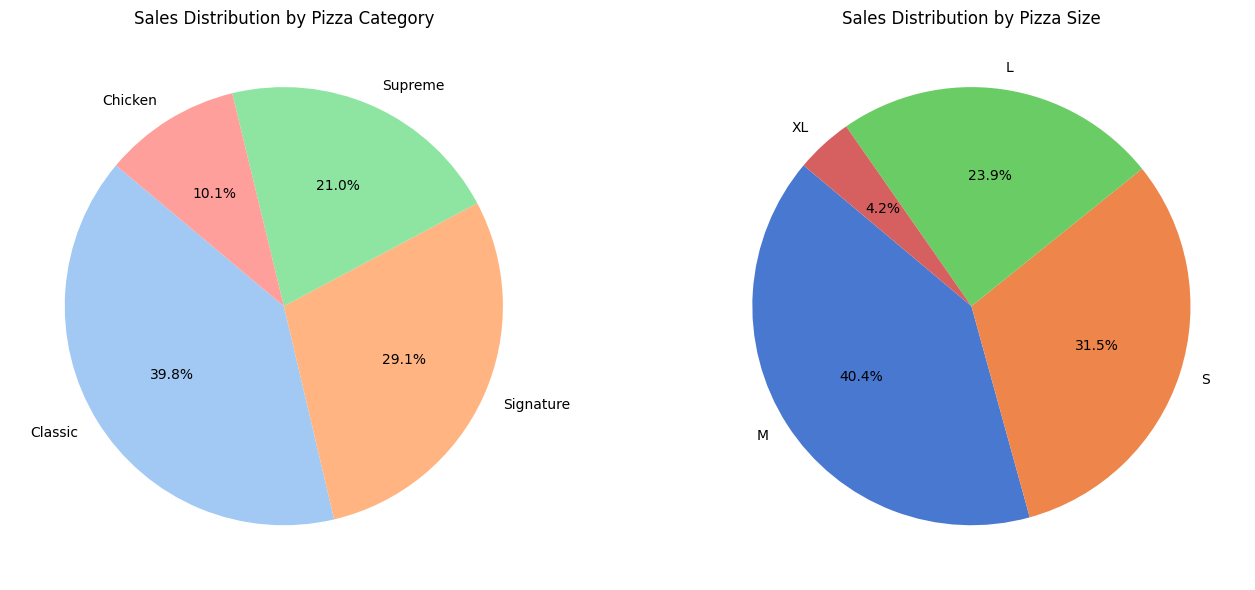

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie Chart 1: Pizza Category Distribution
category_counts = df['pizza_category'].value_counts()
axes[0].pie(category_counts, labels=category_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel')[:4])
axes[0].set_title('Sales Distribution by Pizza Category')

# Pie Chart 2: Pizza Size Distribution
size_counts = df['pizza_size'].value_counts()
axes[1].pie(size_counts, labels=size_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('muted')[:4])
axes[1].set_title('Sales Distribution by Pizza Size')

plt.tight_layout()
plt.show()

## Data Preparation and Splitting
We will encode categorical fields and split the data into training and test sets to predict the **pizza_category**.

In [3]:
# Encode size feature
le_size = LabelEncoder()
df['pizza_size_encoded'] = le_size.fit_transform(df['pizza_size'])

# Encode target label (pizza_category)
le_category = LabelEncoder()
df['category_encoded'] = le_category.fit_transform(df['pizza_category'])

# Features and Target
X = df[['quantity', 'unit_price', 'total_price', 'pizza_size_encoded']]
y = df['category_encoded']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (800, 4)
Testing set shape: (200, 4)


## Model Training & Accuracy Evaluation
We will train a RandomForest Classifier to predict the category of pizza based on order transaction features.

In [4]:
# Initialize and train Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le_category.classes_))

Model Accuracy: 34.00%

Classification Report:
              precision    recall  f1-score   support

     Chicken       0.05      0.06      0.05        18
     Classic       0.46      0.46      0.46        84
   Signature       0.34      0.34      0.34        58
     Supreme       0.21      0.20      0.21        40

    accuracy                           0.34       200
   macro avg       0.27      0.27      0.27       200
weighted avg       0.34      0.34      0.34       200



## Comparison of Actual vs Predicted Data

In [5]:
# Decode predictions and actual labels back to strings
actual_labels = le_category.inverse_transform(y_test)
predicted_labels = le_category.inverse_transform(y_pred)

# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    'Actual Label': actual_labels,
    'Predicted Label': predicted_labels,
    'Is Correct': actual_labels == predicted_labels
})

print("Sample Predictions vs Actual Values:")
display(comparison_df.head(20))

Sample Predictions vs Actual Values:


,Actual Label,Predicted Label,Is Correct
0,Classic,Chicken,False
1,Signature,Signature,True
2,Classic,Signature,False
3,Signature,Classic,False
4,Classic,Signature,False
5,Classic,Supreme,False
6,Classic,Classic,True
7,Signature,Classic,False
8,Classic,Supreme,False
9,Classic,Signature,False


In [6]:
import joblib

# Save the model to a file
model_filename = 'pizza_category_classifier.pkl'
joblib.dump(model, model_filename)
print(f"Model successfully saved to '{model_filename}'")

Model successfully saved to 'pizza_category_classifier.pkl'
